In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

## Data preparation

**Transformers**: NN architecture
* Focusses on understanding relationships within data to process information more efficiently
* Processes and entire sentence at once instead of reading words sequentially (how? no idea bro)

**Tensors**: multidimensional arrays

In [37]:
# Define transformation for images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307), (0.3081))
])

MNIST: dataset of handwritten digits

In [38]:
# Load the training dataset
train_dataset = torchvision.datasets.MNIST(
    root='./data',  # Where to store the dataset
    train=True,     # This is training data
    download=True,  # Download if not present
    transform=transform  # Apply transformations
)

# Load the test dataset
test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

**DataLoader**: utility class, tool for efficiently loading/processing data for DL models
* **Batching**: process the data in batches (smaller chunks, instead of the entire dataset at once) -> reduces memory footprint
* **Shuffling**: shuffle data in each epoch to prevent the model from biased learning
* **Processing**: helps transform data to improve model stability and robustness 


In [39]:
# Create data loaders for batch processing
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Visualise images

In [43]:
# Function to display images
def show_images(images, labels):
    fix, ax = plt.subplots(2, 5, figsize = (10, 4))
    ax = ax.flatten()

    for i in range(10):
        ax[i].imshow(images[i].reshape(28, 28), cmap = "gray")
        ax[i].set_title(f"Label: {labels[i]}")
        ax[i].axis("off")

    plt.tight_layout()
    plt.show()

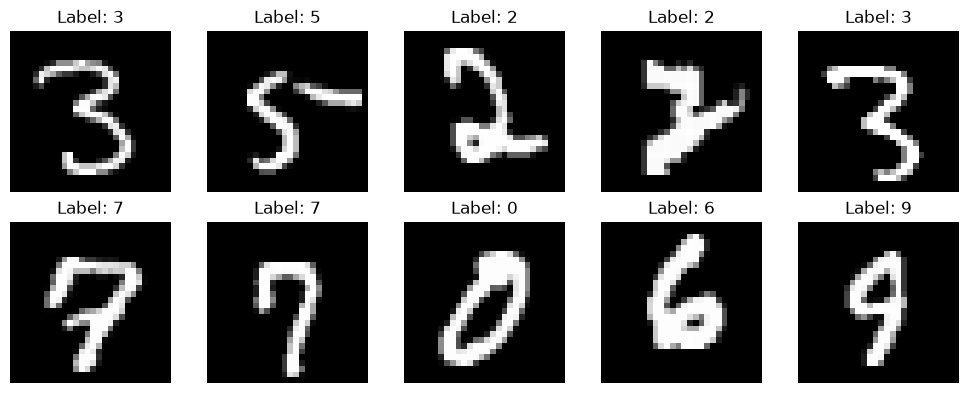

In [44]:
# Get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images 
show_images(images[:10], labels[:10])

## Create NN model

**super()**: to call methods from a parent  class inside a child class
* We're inheriting from the nn.Module here

Neural network consists of:
* **nn.Flatten()** to convert 2D images into 1D vectors
* **nn.Linear(in_features, out_features)** applies a linear relationship to the incoming data
    * **in_features**: size of input sample
    * **out_features**: size of output sample
    * We have three fully connected linear layers. 
* **nn.ReLU** (rectified linear unit function): activation functions between the layers
    * Activation function of a node is a function that calculates the output of the node (based on individual inputs and weights)

In [48]:
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__() 
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x) # Apply ReLU between first and second layer
        x = self.fc2(x)
        x = self.relu(x) # Apply ReLU between the second and third layer
        x = self.fc3(x)
        return x

# Initialise model
model = SimpleNN()
print(model)  

SimpleNN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


## Training the NN

**CrossEntropyLoss()**: way to measure how close the model's predictions are to the labels
* For multiclass classification problems

**optimizer**: improves model by adjusting its parameters (weights and biases) to minimise loss
* SGD: stochastic gradient descent

In [54]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # CrossEntropyLoss for multiclass classification problems
optimizer = optim.SGD(model.parameters(), lr = 0.01, momentum = 0.9)   

# Check if GPU is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

SimpleNN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)

**optimizer.zero_grad()** is to clear the gradients of all optimised tensors
* Avoids that the gradients are accumulated in the .grad attribute of the tensors
* Ensures that the gradients are calculated only based on current data (and not previous data)
* Prevent memory leaks

**Forward pass**: process of passing input data through the layers of a NN to obtain an output

**Backward pass**: calculate gradients
* **optimizer.step()** uses the calculated slope to update the parameters and performs the actual gradient descent

In [67]:
# Training loop
num_epochs = 5
train_losses = []

for epoch in range(num_epochs):
    running_loss = 0.0

    for i, (inputs, labels) in enumerate(train_loader):
        # Move tensors to configures device
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero parameter gradients (crucial step)
        optimizer.zero_grad() 

        # Forward pass 
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Print statistics
        running_loss += loss.item()
        # if (i%1) % 100 == 0:
        #     print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Loss: {running_loss/100:.4f}")
        train_losses.append(running_loss)

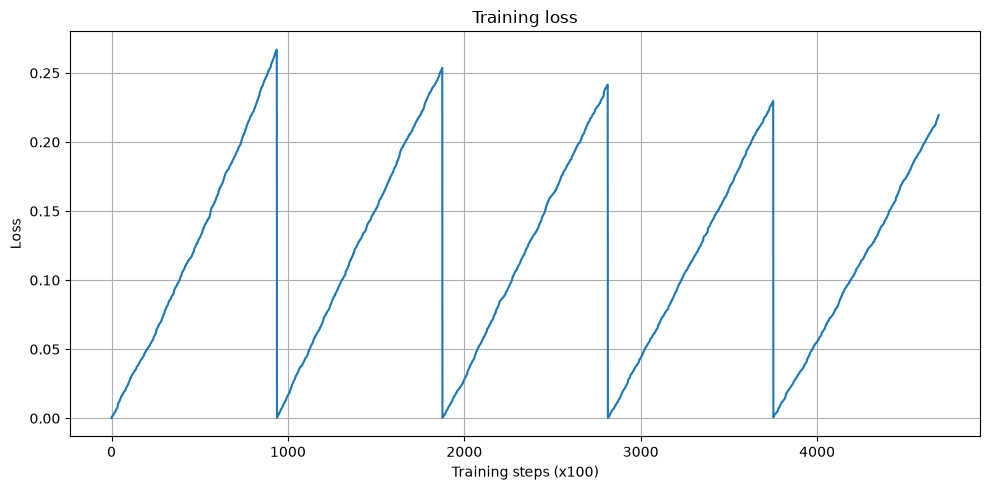

In [70]:
# Visualise training process
plt.figure(figsize = (10, 5))
plt.plot(train_losses)
plt.xlabel("Training steps (x100)")
plt.ylabel("Loss")
plt.title("Training loss")
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate model

In [71]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images) 
        _, predicted = torch.max(outputs.data, 1) # Get predictions from output
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on test set: {accuracy:.2f}%")

Accuracy on test set: 98.24%


## Save and load the model

Save your model so you can use it later without retraining 

In [ ]:
# Save the model
torch.save(model.state_dict(), "models/mnist_test-model_Aliena.pth")

# Load the model
loaded_model = SimpleNN()
loaded_model.load_state_dict(torch.load("models/mnist_test-model_Aliena.pth"))
loaded_model.to(device)
loaded_model.eval()

Model loaded!
